DATA QUALITY CHECK
Rows in input after valid date/NDVI check: 9,557
Rows used in fair comparison:              9,171
Unique pixels:                             200
Unique dates:                              58
Date range:                                2025-01-01 to 2025-12-27
NDVI range:                                0.0501 to 0.9103
NDVI mean:                                 0.4303
Max difference from (B8-B4)/(B8+B4):       1.110e-16

Complete-case data by season:
      season  rows  unique_pixels  unique_dates  NDVI_mean  NDVI_std  NDVI_min  NDVI_max
      Winter  2933            200            17   0.437407  0.177321  0.093792  0.910348
      Summer  3376            200            17   0.343277  0.156489  0.068244  0.908243
     Monsoon   989            200            13   0.474246  0.177346  0.050146  0.891897
Post-Monsoon  1873            200            11   0.553006  0.163409  0.116265  0.903305

EXPERIMENT 1: LEAVE-ONE-SEASON-OUT
Experiment 1 complete.

EXPERIMENT 2: WITHIN-SE

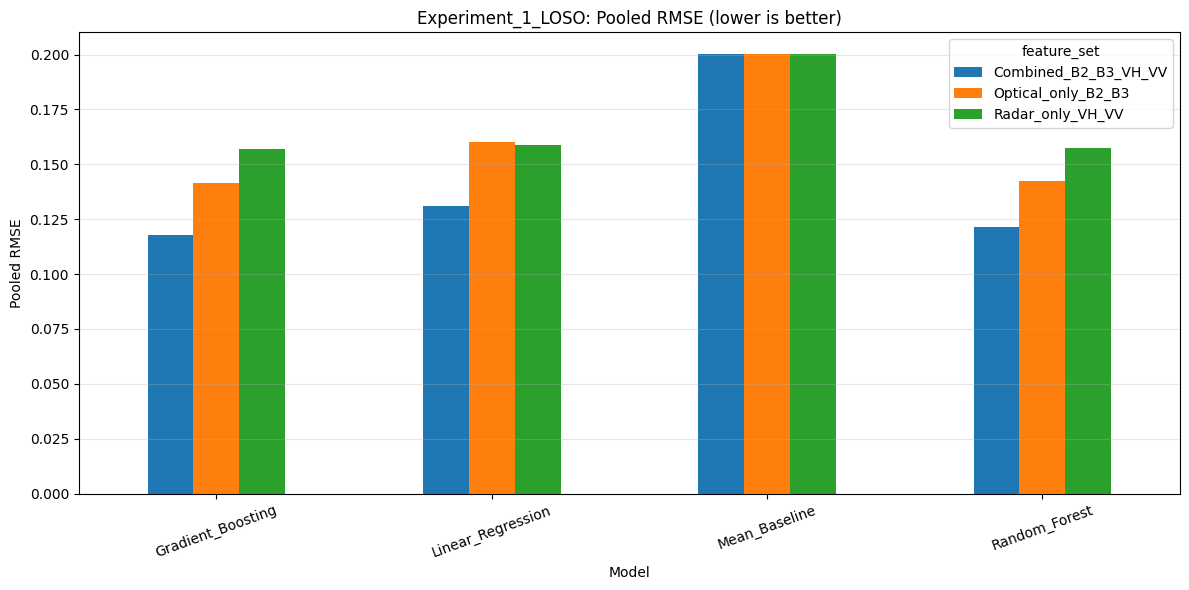

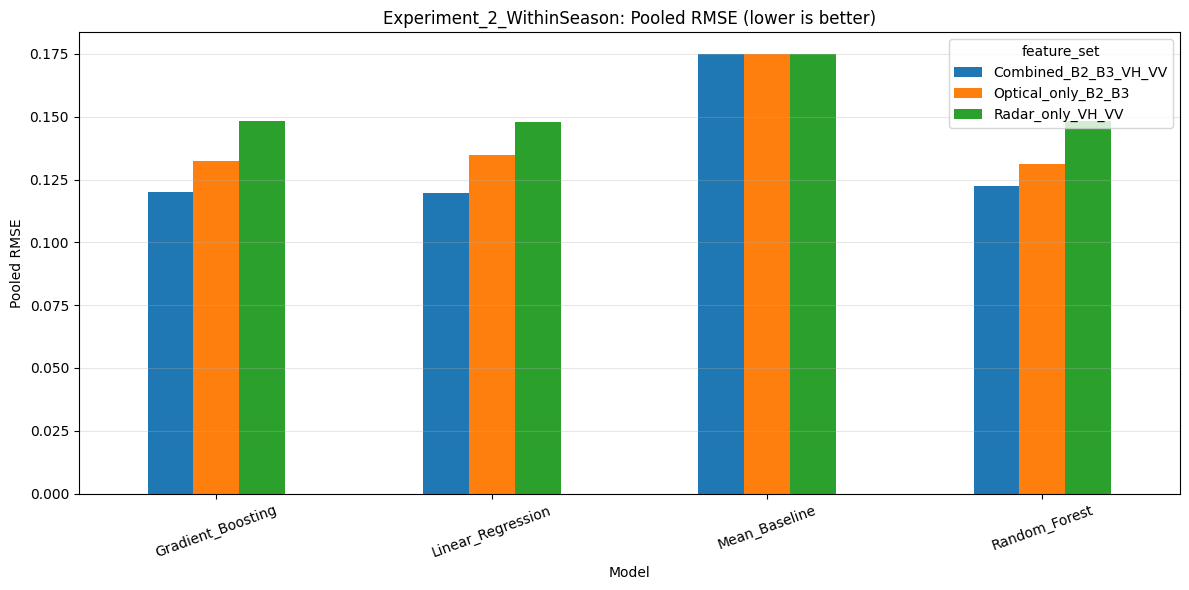

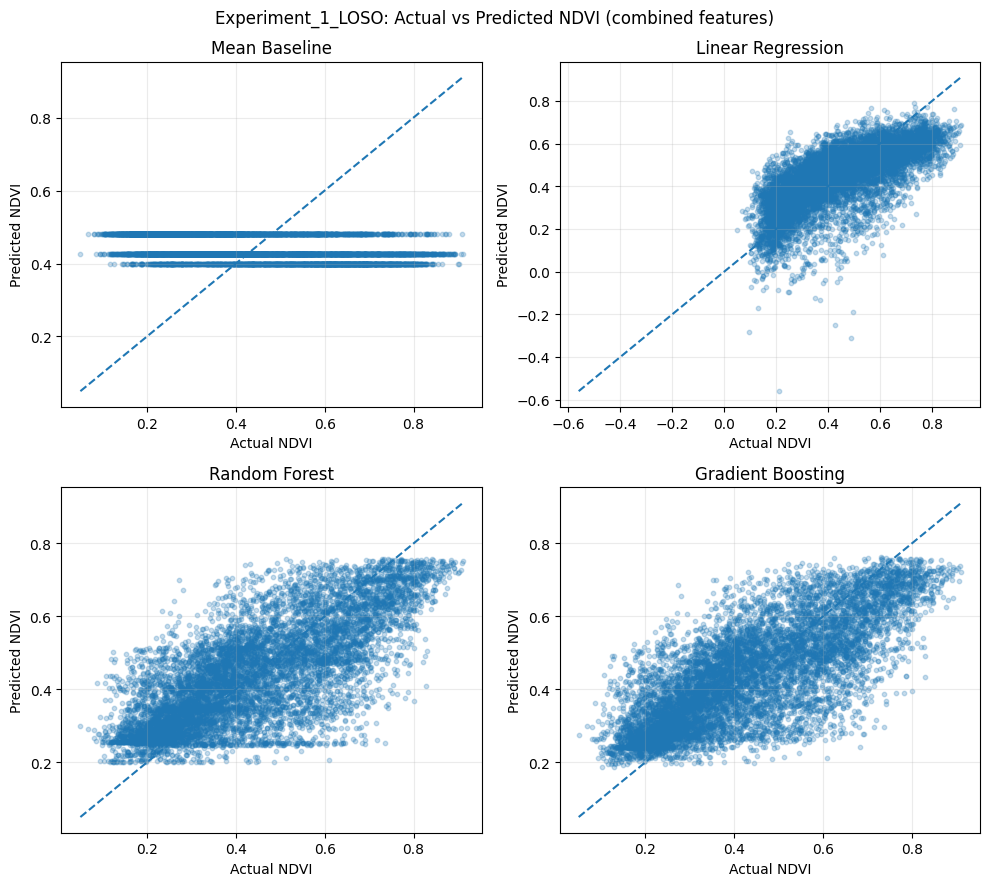

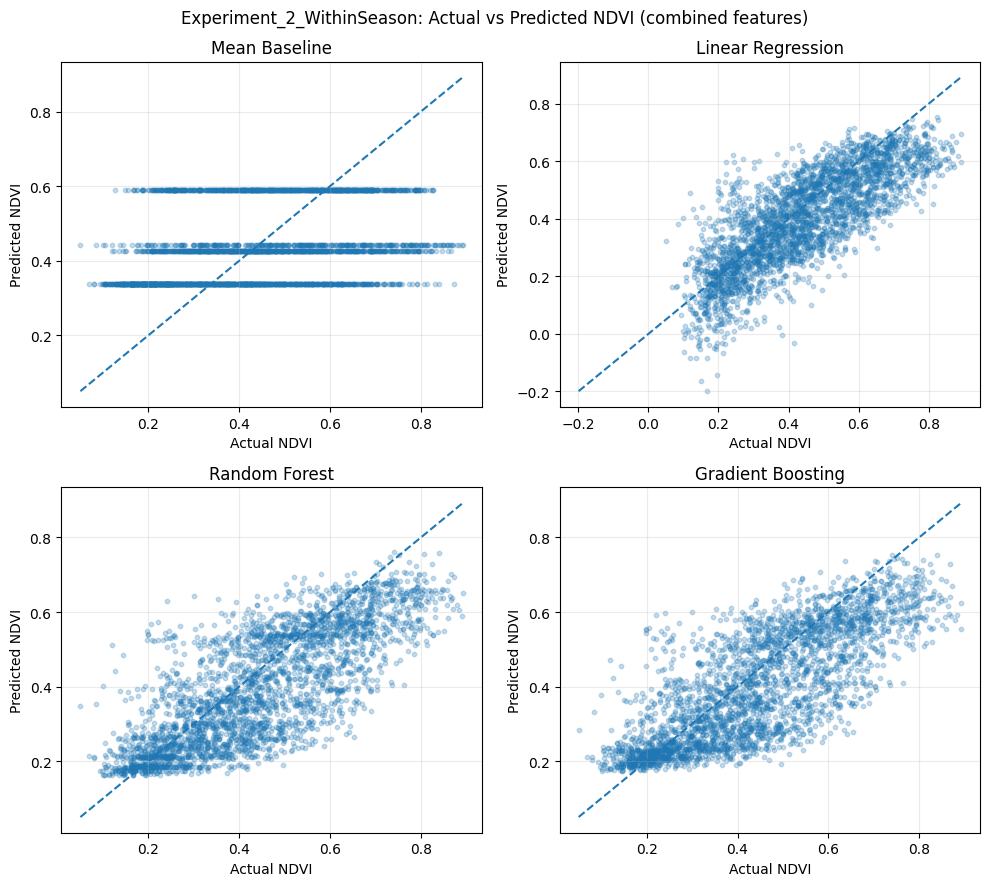


FINISHED
Output folder: /content/ndvi_two_experiments_results
Results ZIP:   /content/ndvi_two_experiments_results.zip

Download ndvi_two_experiments_results.zip from the Colab Files panel.
Please send me that ZIP after the code finishes; it contains the tables,
predictions, data checks, split dates, and plots needed to review the results.


In [2]:
"""
Multi-Sensor Multi-Temporal NDVI Estimation
Two evaluation experiments:
  Experiment 1: Leave-One-Season-Out (LOSO)
  Experiment 2: Within-season chronological date-blocked testing

Designed for Google Colab. Upload the CSV and set CSV_PATH below.
Experiment 2 uses a strictly chronological split (earliest dates train, latest dates test).
The script uses a common complete-case dataset for a fair comparison of:
  - Optical-only: B2, B3
  - Radar-only: VH, VV
  - Combined: B2, B3, VH, VV

Target:
  NDVI, calculated from Sentinel-2 B8 and B4 before this script runs.

IMPORTANT INTERPRETATION:
- LOSO tests transfer to a held-out season; it is NOT a future-year forecast.
- Within-season testing trains on earlier complete observation dates and tests on
  later complete dates within each season. All pixel rows from a date stay together.
  The same pixel locations may appear on training and test dates, so this is temporal
  testing at known locations, not spatial generalization or a future-year forecast.
- Rows with missing VH or VV are removed from ALL feature configurations
  so every configuration is evaluated on the same records.
"""

from pathlib import Path
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore", category=UserWarning)

# ---------------------------------------------------------------------
# 1. FILE LOCATIONS
# ---------------------------------------------------------------------
# In Google Colab, upload the CSV using the Files panel, then set this
# to the exact uploaded filename. For the supplied file, it may be:
CSV_PATH = "/content/CropMonitoring_2025_TimeSeries_v2.csv"

# All output files will be saved in this folder and bundled into a ZIP.
OUT_DIR = Path("/content/ndvi_two_experiments_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
WITHIN_SEASON_TRAIN_FRACTION = 0.70  # earliest 70% of dates train; latest 30% test
MIN_TRAIN_DATES = 3
MIN_TEST_DATES = 2

SEASON_ORDER = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

FEATURE_SETS = {
    "Optical_only_B2_B3": ["B2", "B3"],
    "Radar_only_VH_VV": ["VH", "VV"],
    "Combined_B2_B3_VH_VV": ["B2", "B3", "VH", "VV"],
}


# ---------------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ---------------------------------------------------------------------
def season_of_month(month):
    """Assign each date to the four seasons used in this project."""
    if month in (12, 1, 2):
        return "Winter"
    if month in (3, 4, 5):
        return "Summer"
    if month in (6, 7, 8, 9):
        return "Monsoon"
    return "Post-Monsoon"


def make_models():
    """Return fresh model instances for each train/test split."""
    return {
        "Mean_Baseline": DummyRegressor(strategy="mean"),
        "Linear_Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        "Random_Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=10,
            max_features=0.8,
            random_state=RANDOM_SEED,
            n_jobs=-1
        ),
        "Gradient_Boosting": GradientBoostingRegressor(
            n_estimators=150,
            learning_rate=0.03,
            max_depth=2,
            subsample=0.7,
            random_state=RANDOM_SEED
        ),
    }


def calculate_metrics(y_true, y_pred):
    """Calculate standard regression metrics."""
    return {
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
    }


def fit_evaluate_split(
    data, train, test, features, model_name, model, experiment,
    test_group, train_dates, test_dates, feature_set_name
):
    """Fit one model on one split and return fold metrics + row predictions."""
    if train.empty or test.empty:
        raise ValueError(
            f"Empty train/test split for {experiment}, {test_group}, {model_name}."
        )

    X_train = train[features]
    y_train = train["NDVI"].astype(float)
    X_test = test[features]
    y_test = test["NDVI"].astype(float)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    # Check for unexpected non-finite outputs.
    if not np.isfinite(predictions).all():
        raise ValueError(
            f"Non-finite predictions found for {experiment}/{test_group}/{model_name}."
        )

    metrics = calculate_metrics(y_test, predictions)
    fold_record = {
        "experiment": experiment,
        "feature_set": feature_set_name,
        "model": model_name,
        "test_group": test_group,
        "n_train_rows": int(len(train)),
        "n_test_rows": int(len(test)),
        "n_train_pixels": int(train["pixel_id"].nunique()),
        "n_test_pixels": int(test["pixel_id"].nunique()),
        "n_train_dates": int(train["date"].nunique()),
        "n_test_dates": int(test["date"].nunique()),
        "train_first_date": str(train["date"].min().date()),
        "train_last_date": str(train["date"].max().date()),
        "test_first_date": str(test["date"].min().date()),
        "test_last_date": str(test["date"].max().date()),
        **metrics,
    }

    pred_frame = pd.DataFrame({
        "experiment": experiment,
        "feature_set": feature_set_name,
        "model": model_name,
        "test_group": test_group,
        "pixel_id": test["pixel_id"].to_numpy(),
        "date": test["date"].to_numpy(),
        "actual_NDVI": y_test.to_numpy(),
        "predicted_NDVI": predictions,
    })
    pred_frame["error_pred_minus_actual"] = (
        pred_frame["predicted_NDVI"] - pred_frame["actual_NDVI"]
    )
    pred_frame["absolute_error"] = pred_frame["error_pred_minus_actual"].abs()
    return fold_record, pred_frame


# ---------------------------------------------------------------------
# 3. LOAD AND CHECK DATA
# ---------------------------------------------------------------------
if not Path(CSV_PATH).exists():
    raise FileNotFoundError(
        f"CSV not found: {CSV_PATH}\n"
        "In Colab, upload your CSV and update CSV_PATH to the exact filename."
    )

raw = pd.read_csv(CSV_PATH)
input_file_rows = len(raw)

required_columns = [
    "pixel_id", "date", "B2", "B3", "B4", "B8", "NDVI", "VH", "VV"
]
missing_columns = [c for c in required_columns if c not in raw.columns]
if missing_columns:
    raise ValueError(
        f"The CSV is missing required columns: {missing_columns}\n"
        f"Columns found: {raw.columns.tolist()}"
    )

raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
numeric_columns = ["pixel_id", "B2", "B3", "B4", "B8", "NDVI", "VH", "VV"]
for col in numeric_columns:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

raw = raw.replace([np.inf, -np.inf], np.nan)
raw = raw.dropna(subset=["pixel_id", "date", "NDVI"]).copy()
raw["pixel_id"] = raw["pixel_id"].astype(int)
raw["season"] = raw["date"].dt.month.map(season_of_month)

# The provided GEE code defines NDVI from B8 and B4. Check this rather than
# silently replacing the target. Tiny floating-point differences are expected.
ndvi_calculated = (raw["B8"] - raw["B4"]) / (raw["B8"] + raw["B4"])
ndvi_diff = (raw["NDVI"] - ndvi_calculated).abs()
ndvi_check_max_abs_diff = float(ndvi_diff.max(skipna=True))

# Use one common complete-case dataset for all sensor feature sets.
# This removes records missing any of B2, B3, VH, VV, or NDVI.
predictors_all = ["B2", "B3", "VH", "VV"]
n_before_common = len(raw)
data = raw.dropna(subset=predictors_all + ["NDVI", "date", "season"]).copy()
data = data.sort_values(["date", "pixel_id"]).reset_index(drop=True)

# Basic consistency checks.
duplicate_pixel_dates = int(data.duplicated(["pixel_id", "date"]).sum())
if duplicate_pixel_dates:
    raise ValueError(
        f"Found {duplicate_pixel_dates} duplicate pixel_id/date rows. "
        "Please resolve duplicates before evaluating models."
    )

if data["season"].nunique() != 4:
    raise ValueError(
        "The complete-case dataset does not contain all four seasons. "
        "Check data availability before proceeding."
    )

quality = pd.DataFrame([
    ("input_file_rows", input_file_rows),
    ("rows_removed_for_invalid_pixel_date_or_NDVI", input_file_rows - len(raw)),
    ("rows_removed_for_missing_predictors", n_before_common - len(data)),
    ("complete_case_rows_used", len(data)),
    ("unique_pixels_in_complete_data", data["pixel_id"].nunique()),
    ("unique_dates_in_complete_data", data["date"].nunique()),
    ("first_date_in_complete_data", str(data["date"].min().date())),
    ("last_date_in_complete_data", str(data["date"].max().date())),
    ("NDVI_min", data["NDVI"].min()),
    ("NDVI_max", data["NDVI"].max()),
    ("NDVI_mean", data["NDVI"].mean()),
    ("max_abs_difference_NDVI_vs_B8_B4_formula", ndvi_check_max_abs_diff),
    ("duplicate_pixel_date_rows", duplicate_pixel_dates),
], columns=["measure", "value"])
quality.to_csv(OUT_DIR / "data_quality_report.csv", index=False)

season_quality = (
    data.groupby("season")
    .agg(
        rows=("NDVI", "size"),
        unique_pixels=("pixel_id", "nunique"),
        unique_dates=("date", "nunique"),
        NDVI_mean=("NDVI", "mean"),
        NDVI_std=("NDVI", "std"),
        NDVI_min=("NDVI", "min"),
        NDVI_max=("NDVI", "max"),
    )
    .reindex(SEASON_ORDER)
    .reset_index()
)
season_quality.to_csv(OUT_DIR / "data_quality_by_season.csv", index=False)

print("=" * 75)
print("DATA QUALITY CHECK")
print("=" * 75)
print(f"Rows in input after valid date/NDVI check: {len(raw):,}")
print(f"Rows used in fair comparison:              {len(data):,}")
print(f"Unique pixels:                             {data['pixel_id'].nunique():,}")
print(f"Unique dates:                              {data['date'].nunique():,}")
print(f"Date range:                                {data['date'].min().date()} to {data['date'].max().date()}")
print(f"NDVI range:                                {data['NDVI'].min():.4f} to {data['NDVI'].max():.4f}")
print(f"NDVI mean:                                 {data['NDVI'].mean():.4f}")
print(f"Max difference from (B8-B4)/(B8+B4):       {ndvi_check_max_abs_diff:.3e}")
print("\nComplete-case data by season:")
print(season_quality.to_string(index=False))


# ---------------------------------------------------------------------
# 4. EXPERIMENT 1: LEAVE-ONE-SEASON-OUT (LOSO)
# ---------------------------------------------------------------------
# Each season is tested once. Training includes all records from the other
# three seasons. This tests cross-season transfer, not future-year forecasting.
fold_records = []
prediction_frames = []

print("\n" + "=" * 75)
print("EXPERIMENT 1: LEAVE-ONE-SEASON-OUT")
print("=" * 75)

for feature_set_name, features in FEATURE_SETS.items():
    for test_season in SEASON_ORDER:
        test_mask = data["season"].eq(test_season)
        train = data.loc[~test_mask].copy()
        test = data.loc[test_mask].copy()

        if train.empty or test.empty:
            raise ValueError(f"Empty LOSO split for season {test_season}.")

        # The split is identical for all models and feature sets.
        train_dates = sorted(train["date"].dt.strftime("%Y-%m-%d").unique())
        test_dates = sorted(test["date"].dt.strftime("%Y-%m-%d").unique())

        for model_name, model in make_models().items():
            fold_record, pred_frame = fit_evaluate_split(
                data=data,
                train=train,
                test=test,
                features=features,
                model_name=model_name,
                model=model,
                experiment="Experiment_1_LOSO",
                test_group=test_season,
                train_dates=train_dates,
                test_dates=test_dates,
                feature_set_name=feature_set_name,
            )
            fold_records.append(fold_record)
            prediction_frames.append(pred_frame)

print("Experiment 1 complete.")


# ---------------------------------------------------------------------
# 5. EXPERIMENT 2: WITHIN-SEASON CHRONOLOGICAL DATE-BLOCKED TESTING
# ---------------------------------------------------------------------
# IMPORTANT: this is a chronological split, NOT a random split.
# Within each season, sort the actual observation dates from earliest to latest.
# The earliest 70% of unique dates are used for training; the latest 30% are
# held out for testing. All pixel rows from one date remain in the same split.
# This is a temporal holdout at the sampled, known locations. It is not a
# test on unseen locations and it is not a future-year forecast.
#
# Winter includes January/February and December. Sorting by the actual calendar
# date correctly places January/February before December in this one-year data.
print("\n" + "=" * 75)
print("EXPERIMENT 2: WITHIN-SEASON CHRONOLOGICAL DATE-BLOCKED TESTING")
print("=" * 75)

within_split_records = []

for season in SEASON_ORDER:
    season_data = data.loc[data["season"].eq(season)].copy()
    unique_dates = pd.DatetimeIndex(season_data["date"].dropna().unique()).sort_values()
    n_dates = len(unique_dates)

    if n_dates < (MIN_TRAIN_DATES + MIN_TEST_DATES):
        raise ValueError(
            f"{season} has only {n_dates} complete dates. Need at least "
            f"{MIN_TRAIN_DATES + MIN_TEST_DATES} to perform the planned split."
        )

    # Earliest dates train; latest dates test. Keep at least the configured
    # minimum number of dates in each side.
    n_train_dates = int(np.floor(n_dates * WITHIN_SEASON_TRAIN_FRACTION))
    n_train_dates = max(MIN_TRAIN_DATES, n_train_dates)
    n_train_dates = min(n_train_dates, n_dates - MIN_TEST_DATES)

    train_date_values = set(unique_dates[:n_train_dates])
    test_date_values = set(unique_dates[n_train_dates:])

    train = season_data.loc[season_data["date"].isin(train_date_values)].copy()
    test = season_data.loc[season_data["date"].isin(test_date_values)].copy()

    train_unique_dates = pd.DatetimeIndex(train["date"].unique()).sort_values()
    test_unique_dates = pd.DatetimeIndex(test["date"].unique()).sort_values()

    # Hard checks: no shared dates and every training date must be earlier
    # than every testing date. This catches accidental random/interleaved splits.
    overlap = set(train_unique_dates).intersection(set(test_unique_dates))
    if overlap:
        raise AssertionError(f"Date leakage found in {season}: {overlap}")
    if train_unique_dates.max() >= test_unique_dates.min():
        raise AssertionError(
            f"Chronological split failed for {season}: latest train date "
            f"({train_unique_dates.max().date()}) is not earlier than earliest "
            f"test date ({test_unique_dates.min().date()})."
        )

    train_dates = train_unique_dates.strftime("%Y-%m-%d").tolist()
    test_dates = test_unique_dates.strftime("%Y-%m-%d").tolist()

    within_split_records.append({
        "season": season,
        "split_method": "chronological_earliest_train_latest_test",
        "train_fraction_requested": WITHIN_SEASON_TRAIN_FRACTION,
        "n_available_dates": n_dates,
        "n_train_dates": len(train_unique_dates),
        "n_test_dates": len(test_unique_dates),
        "train_first_date": train_dates[0],
        "train_last_date": train_dates[-1],
        "test_first_date": test_dates[0],
        "test_last_date": test_dates[-1],
        "train_dates_list": ";".join(train_dates),
        "test_dates_list": ";".join(test_dates),
        "n_train_rows": len(train),
        "n_test_rows": len(test),
        "n_train_pixels": train["pixel_id"].nunique(),
        "n_test_pixels": test["pixel_id"].nunique(),
        "chronology_check_passed": True,
        "shared_dates_count": 0,
    })

    print(
        f"{season:14s}: {len(train_unique_dates)} training dates "
        f"({train_dates[0]} to {train_dates[-1]}); "
        f"{len(test_unique_dates)} test dates "
        f"({test_dates[0]} to {test_dates[-1]})"
    )

    for feature_set_name, features in FEATURE_SETS.items():
        for model_name, model in make_models().items():
            fold_record, pred_frame = fit_evaluate_split(
                data=data,
                train=train,
                test=test,
                features=features,
                model_name=model_name,
                model=model,
                experiment="Experiment_2_WithinSeason",
                test_group=season,
                train_dates=train_dates,
                test_dates=test_dates,
                feature_set_name=feature_set_name,
            )
            fold_records.append(fold_record)
            prediction_frames.append(pred_frame)

pd.DataFrame(within_split_records).to_csv(
    OUT_DIR / "experiment_2_date_splits.csv", index=False
)
print("Experiment 2 complete. All chronological split checks passed.")

# ---------------------------------------------------------------------
# 6. SAVE FOLD RESULTS AND ALL TEST PREDICTIONS
# ---------------------------------------------------------------------
folds = pd.DataFrame(fold_records)
predictions = pd.concat(prediction_frames, ignore_index=True)

folds.to_csv(OUT_DIR / "fold_results.csv", index=False)
predictions.to_csv(OUT_DIR / "all_test_predictions.csv", index=False)

# Mean of fold metrics: each season contributes equally.
mean_fold_summary = (
    folds.groupby(["experiment", "feature_set", "model"], as_index=False)
    .agg(
        mean_fold_R2=("R2", "mean"),
        std_fold_R2=("R2", "std"),
        mean_fold_RMSE=("RMSE", "mean"),
        mean_fold_MAE=("MAE", "mean"),
        folds_evaluated=("test_group", "nunique"),
    )
)

# Pooled metrics: concatenate all out-of-sample predictions for a given
# experiment/model/feature set, then calculate metrics once. This is useful
# because seasonal fold sizes differ. Report both pooled and fold-mean values.
pooled_records = []
for (experiment, feature_set, model), group in predictions.groupby(
    ["experiment", "feature_set", "model"]
):
    metrics = calculate_metrics(group["actual_NDVI"], group["predicted_NDVI"])
    pooled_records.append({
        "experiment": experiment,
        "feature_set": feature_set,
        "model": model,
        "pooled_test_rows": len(group),
        "pooled_R2": metrics["R2"],
        "pooled_RMSE": metrics["RMSE"],
        "pooled_MAE": metrics["MAE"],
    })
pooled_summary = pd.DataFrame(pooled_records)

summary = mean_fold_summary.merge(
    pooled_summary, on=["experiment", "feature_set", "model"], how="outer"
)
summary.to_csv(OUT_DIR / "model_summary.csv", index=False)

# Seasonal/within-season fold-level comparison table.
folds.sort_values(
    ["experiment", "feature_set", "test_group", "RMSE"]
).to_csv(OUT_DIR / "fold_results_sorted.csv", index=False)

print("\n" + "=" * 75)
print("MODEL SUMMARY — MEAN OF FOLD METRICS")
print("=" * 75)
display_cols = [
    "experiment", "feature_set", "model",
    "mean_fold_R2", "mean_fold_RMSE", "mean_fold_MAE",
    "pooled_R2", "pooled_RMSE", "pooled_MAE",
]
print(summary[display_cols].round(4).to_string(index=False))


# ---------------------------------------------------------------------
# 7. CREATE SIMPLE PLOTS
# ---------------------------------------------------------------------
# Plot 1: pooled RMSE by model and feature set, separately per experiment.
for experiment in ["Experiment_1_LOSO", "Experiment_2_WithinSeason"]:
    sub = summary.loc[summary["experiment"].eq(experiment)].copy()
    if sub.empty:
        continue

    pivot = sub.pivot(index="model", columns="feature_set", values="pooled_RMSE")
    ax = pivot.plot(kind="bar", figsize=(12, 6))
    ax.set_title(f"{experiment}: Pooled RMSE (lower is better)")
    ax.set_xlabel("Model")
    ax.set_ylabel("Pooled RMSE")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plot_name = (
        "experiment_1_loso_pooled_rmse.png"
        if experiment == "Experiment_1_LOSO"
        else "experiment_2_within_season_pooled_rmse.png"
    )
    plt.savefig(OUT_DIR / plot_name, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

# Plot 2: Actual vs predicted NDVI for the combined feature set.
for experiment in ["Experiment_1_LOSO", "Experiment_2_WithinSeason"]:
    sub = predictions.loc[
        predictions["experiment"].eq(experiment)
        & predictions["feature_set"].eq("Combined_B2_B3_VH_VV")
    ].copy()
    if sub.empty:
        continue

    fig, axes = plt.subplots(2, 2, figsize=(10, 9))
    axes = axes.ravel()
    model_order = [
        "Mean_Baseline", "Linear_Regression", "Random_Forest", "Gradient_Boosting"
    ]
    for ax, model_name in zip(axes, model_order):
        model_data = sub.loc[sub["model"].eq(model_name)]
        ax.scatter(
            model_data["actual_NDVI"],
            model_data["predicted_NDVI"],
            alpha=0.25,
            s=10
        )
        lo = min(model_data["actual_NDVI"].min(), model_data["predicted_NDVI"].min())
        hi = max(model_data["actual_NDVI"].max(), model_data["predicted_NDVI"].max())
        ax.plot([lo, hi], [lo, hi], linestyle="--")
        ax.set_title(model_name.replace("_", " "))
        ax.set_xlabel("Actual NDVI")
        ax.set_ylabel("Predicted NDVI")
        ax.grid(alpha=0.25)
    fig.suptitle(f"{experiment}: Actual vs Predicted NDVI (combined features)")
    fig.tight_layout()
    plot_name = (
        "experiment_1_loso_actual_vs_predicted.png"
        if experiment == "Experiment_1_LOSO"
        else "experiment_2_within_season_actual_vs_predicted.png"
    )
    fig.savefig(OUT_DIR / plot_name, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ---------------------------------------------------------------------
# 8. ZIP ALL RESULTS FOR EASY SHARING
# ---------------------------------------------------------------------
zip_path = Path("/content/ndvi_two_experiments_results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in OUT_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.relative_to(OUT_DIR.parent))

print("\n" + "=" * 75)
print("FINISHED")
print("=" * 75)
print(f"Output folder: {OUT_DIR}")
print(f"Results ZIP:   {zip_path}")
print("\nDownload ndvi_two_experiments_results.zip from the Colab Files panel.")
print("Please send me that ZIP after the code finishes; it contains the tables,")
print("predictions, data checks, split dates, and plots needed to review the results.")
